# L01 appliqué au projet — préparation et exploration des données : diagnostic, fuite et corrélation

**Projet :** détection automatique des transactions bancaires frauduleuses
**Données :** *Credit Card Fraud* (ULB / Worldline, Dal Pozzolo et al.) — transactions européennes de
septembre 2013 : 284 807 transactions, dont 492 fraudes (≈ 0,17 %).

## Contexte

Colonnes : `Time` (secondes depuis la 1ʳᵉ transaction), `V1`…`V28` (composantes issues d'une ACP,
anonymisées), `Amount` (montant), `Class` (1 = fraude, 0 = légitime).

Comme dans le lab, on n'entraîne **aucun modèle** ici : on regarde les données, puis on les prépare
sans les faire fuir, et on vérifie ce que disent (ou cachent) les corrélations.

Chaque cellule de vérification affiche `OK` ou `ECHEC` avec la propriété violée.

**À placer dans le même dossier que le fichier CSV.**

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

GRAINE = 0
np.random.seed(GRAINE)
FICHIER = "redit Card Fraud — Dal Pozzolo et al. [1].csv"

# si le nom exact pose problème : le CSV qui contient « Pozzolo », sinon creditcard.csv (Kaggle)
if not Path(FICHIER).exists():
    candidats_csv = list(Path(".").glob("*Pozzolo*.csv")) + list(Path(".").glob("creditcard*.csv"))
    if not candidats_csv:
        raise FileNotFoundError("CSV introuvable : placez creditcard.csv (Kaggle) à côté du notebook")
    FICHIER = candidats_csv[0]

donnees = pd.read_csv(FICHIER)
MESURES = [c for c in donnees.columns if c != "Class"]   # Time, V1…V28, Amount
CATEGORIES = []                                          # aucune colonne texte
CIBLE = "Class"


def verifier(exercice, condition, message):
    """Affiche OK, ou ECHEC avec la propriété violée (même esprit que le lab)."""
    print(f"[{exercice}] OK" if condition else f"[{exercice}] ECHEC : {message}")


print("dimensions :", donnees.shape)
print(len(MESURES), "colonnes numériques :", MESURES[:3], "…", MESURES[-2:])
donnees.head()

dimensions : (284807, 31)
30 colonnes numériques : ['Time', 'V1', 'V2'] … ['V28', 'Amount']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**Rôle des colonnes.** Contrairement aux manchots, ce jeu de données n'a **aucune colonne
catégorielle** : tout est numérique. La cible `Class` est binaire et très déséquilibrée.

## Exercice 1 — diagnostiquer avant de traiter

`diagnostiquer(donnees)` renvoie un dictionnaire :
- `"manquants"` : valeurs manquantes par colonne, pour les seules colonnes qui en ont ;
- `"lignes_sans_mesure"` : lignes où toutes les mesures sont absentes ;
- `"aberrants"` : pour chaque mesure, le nombre de valeurs hors de l'intervalle de Tukey
  [Q1 − 1,5 (Q3 − Q1) ; Q3 + 1,5 (Q3 − Q1)] ;
- `"effectifs_classes"` et `"proportions_classes"` : effectif et part de chaque classe ;
- `"doublons"` : nombre de lignes dupliquées (ajout utile pour ce jeu de données).

On ne traite rien ici : on établit d'abord ce que contiennent les données.

In [2]:
def diagnostiquer(donnees):
    manquants = donnees.isna().sum()
    aberrants = {}
    for colonne in MESURES:
        q1, q3 = donnees[colonne].quantile([0.25, 0.75])
        ecart = q3 - q1
        hors = (donnees[colonne] < q1 - 1.5 * ecart) | (donnees[colonne] > q3 + 1.5 * ecart)
        aberrants[colonne] = int(hors.sum())
    return {
        "manquants": {c: int(n) for c, n in manquants.items() if n > 0},
        "lignes_sans_mesure": int(donnees[MESURES].isna().all(axis=1).sum()),
        "aberrants": aberrants,
        "effectifs_classes": {str(k): int(v) for k, v in donnees[CIBLE].value_counts().items()},
        "proportions_classes": {str(k): round(float(v), 5)
                                for k, v in donnees[CIBLE].value_counts(normalize=True).items()},
        "doublons": int(donnees.duplicated().sum()),
    }


diag = diagnostiquer(donnees)
print("valeurs manquantes   :", diag["manquants"] or "aucune")
print("lignes sans mesure   :", diag["lignes_sans_mesure"])
print("lignes dupliquées    :", diag["doublons"])
print("effectifs par classe :", diag["effectifs_classes"])
print("proportions          :", diag["proportions_classes"])
print()
aberr = pd.Series(diag["aberrants"]).sort_values(ascending=False)
print("valeurs hors intervalle de Tukey (10 colonnes les plus touchées) :")
print(aberr.head(10).to_string())

valeurs manquantes   : aucune
lignes sans mesure   : 0
lignes dupliquées    : 1081
effectifs par classe : {'0': 284315, '1': 492}
proportions          : {'0': 0.99827, '1': 0.00173}

valeurs hors intervalle de Tukey (10 colonnes les plus touchées) :
V27       39163
Amount    31904
V28       30342
V20       27770
V8        24134
V6        22965
V23       18541
V12       15348
V21       14497
V14       14149


In [3]:
cles = {"manquants", "lignes_sans_mesure", "aberrants", "effectifs_classes",
        "proportions_classes", "doublons"}
verifier("L01-E1", set(diag) == cles, "les clés attendues ne sont pas toutes présentes")
verifier("L01-E1", all(n > 0 for n in diag["manquants"].values()),
         "des colonnes sans valeur manquante figurent dans le décompte")
verifier("L01-E1", set(diag["aberrants"]) == set(MESURES),
         "le décompte des aberrants ne couvre pas exactement les mesures")
verifier("L01-E1", sum(diag["effectifs_classes"].values()) == len(donnees),
         "les effectifs par classe ne couvrent pas toutes les lignes")
verifier("L01-E1", diag["doublons"] == int(donnees.duplicated().sum()),
         "le nombre de doublons ne correspond pas au fichier")

[L01-E1] OK
[L01-E1] OK
[L01-E1] OK
[L01-E1] OK


[L01-E1] OK


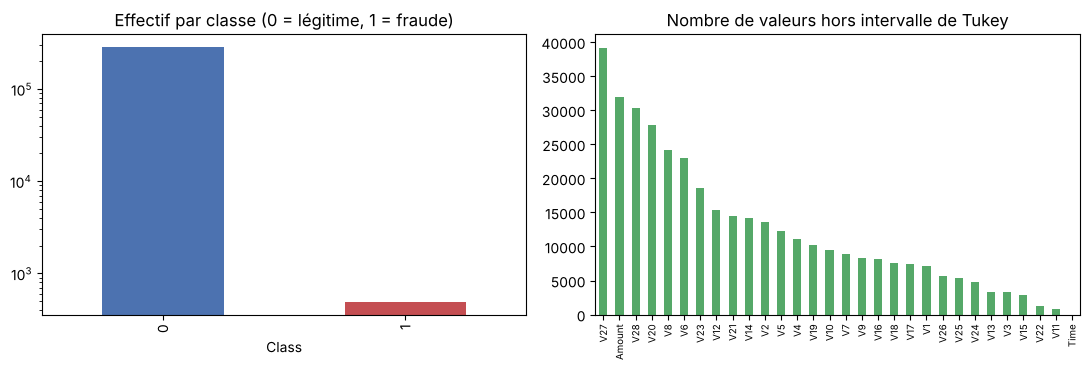

In [4]:
# visualiser le déséquilibre et les aberrants par colonne
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
donnees[CIBLE].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Effectif par classe (0 = légitime, 1 = fraude)")
ax[0].set_yscale("log")
aberr.plot.bar(ax=ax[1], color="#55A868")
ax[1].set_title("Nombre de valeurs hors intervalle de Tukey")
ax[1].tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.show()

**Lecture du diagnostic.**
1. **Pas de valeur manquante** : rien à imputer (l'imputation reste dans le pipeline par sécurité,
   pour de futures transactions).
2. **Des doublons existent** : ils sont à retirer **avant** la séparation, sinon une même transaction
   peut se retrouver à la fois dans l'entraînement et dans le test — c'est une autre forme de fuite.
3. **Beaucoup de valeurs « aberrantes » au sens de Tukey.** Ici, on ne les supprime pas : les fraudes
   sont justement des transactions atypiques ; les retirer reviendrait à effacer une partie de ce
   qu'on cherche à détecter. Comme le dit le corrigé, un diagnostic sert aussi à décider de ne pas
   traiter.
4. **Le déséquilibre est extrême** (≈ 0,17 % de fraudes) : prédire toujours « légitime » donnerait
   99,83 % d'exactitude. La **stratification** est indispensable, et il faudra s'en souvenir au moment
   d'évaluer (précision, rappel, F1, AUPRC).

## Exercice 1 bis — diviser le jeu de données par classe

On sépare le jeu de données en deux sous-ensembles : les transactions **légitimes** (`Class = 0`) et
les **fraudes** (`Class = 1`), puis on compare les deux groupes. C'est encore du diagnostic : on
observe, on ne modifie rien.

`diviser_par_classe(donnees)` renvoie un dictionnaire `{"légitime": ..., "fraude": ...}` contenant
les deux tableaux.

In [5]:
def diviser_par_classe(donnees):
    return {"légitime": donnees[donnees[CIBLE] == 0],
            "fraude": donnees[donnees[CIBLE] == 1]}


groupes = diviser_par_classe(donnees)
legitimes, fraudes = groupes["légitime"], groupes["fraude"]
for nom, groupe in groupes.items():
    print(f"{nom:<9} : {groupe.shape[0]:>7} transactions, {groupe.shape[1]} colonnes, "
          f"dont {int(groupe.duplicated().sum())} doublons")

légitime  :  284315 transactions, 31 colonnes, dont 1062 doublons
fraude    :     492 transactions, 31 colonnes, dont 19 doublons


In [6]:
verifier("L01-E1bis", len(legitimes) + len(fraudes) == len(donnees),
         "des transactions ont été perdues ou comptées deux fois")
verifier("L01-E1bis", (legitimes[CIBLE] == 0).all() and (fraudes[CIBLE] == 1).all(),
         "un sous-ensemble contient des transactions de l'autre classe")
verifier("L01-E1bis", len(fraudes) == diag["effectifs_classes"]["1"],
         "le nombre de fraudes ne correspond pas au diagnostic")

[L01-E1bis] OK
[L01-E1bis] OK
[L01-E1bis] OK


### Comparer les deux classes

Les variables n'ont pas la même échelle (`Time` va jusqu'à 172 792, les `V` restent proches de 0).
Pour comparer les écarts entre classes, on divise donc l'écart des moyennes par l'écart-type de la
variable : c'est l'**écart standardisé**. Un écart de −7 signifie que la moyenne des fraudes est
7 écarts-types en dessous de celle des transactions légitimes.

In [7]:
par_classe = pd.DataFrame({
    "moyenne légitime": legitimes[MESURES].mean(),
    "moyenne fraude": fraudes[MESURES].mean(),
})
par_classe["écart standardisé"] = ((par_classe["moyenne fraude"] - par_classe["moyenne légitime"])
                                   / donnees[MESURES].std())
par_classe = par_classe.reindex(par_classe["écart standardisé"].abs().sort_values(ascending=False).index)
print("variables qui distinguent le plus les deux classes :")
print(par_classe.head(10).to_string(float_format="%.3f"))
print()
print("variables qui ne les distinguent presque pas :")
print(par_classe.tail(5).to_string(float_format="%.3f"))

variables qui distinguent le plus les deux classes :
     moyenne légitime  moyenne fraude  écart standardisé
V17             0.012          -6.666             -7.862
V14             0.012          -6.972             -7.285
V12             0.011          -6.259             -6.275
V10             0.010          -5.677             -5.223
V16             0.007          -4.140             -4.733
V3              0.012          -7.033             -4.647
V7              0.010          -5.569             -4.509
V11            -0.007           3.800              3.729
V4             -0.008           4.542              3.213
V18             0.004          -2.246             -2.685

variables qui ne les distinguent presque pas :
     moyenne légitime  moyenne fraude  écart standardisé
V26            -0.000           0.052              0.107
V15             0.000          -0.093             -0.102
V25            -0.000           0.041              0.080
V23             0.000          -0.040       

In [8]:
# le montant mérite un regard à part : la moyenne seule est trompeuse
print(pd.DataFrame({nom: g["Amount"].describe() for nom, g in groupes.items()})
      .to_string(float_format="%.2f"))

       légitime  fraude
count 284315.00  492.00
mean      88.29  122.21
std      250.11  256.68
min        0.00    0.00
25%        5.65    1.00
50%       22.00    9.25
75%       77.05  105.89
max    25691.16 2125.87


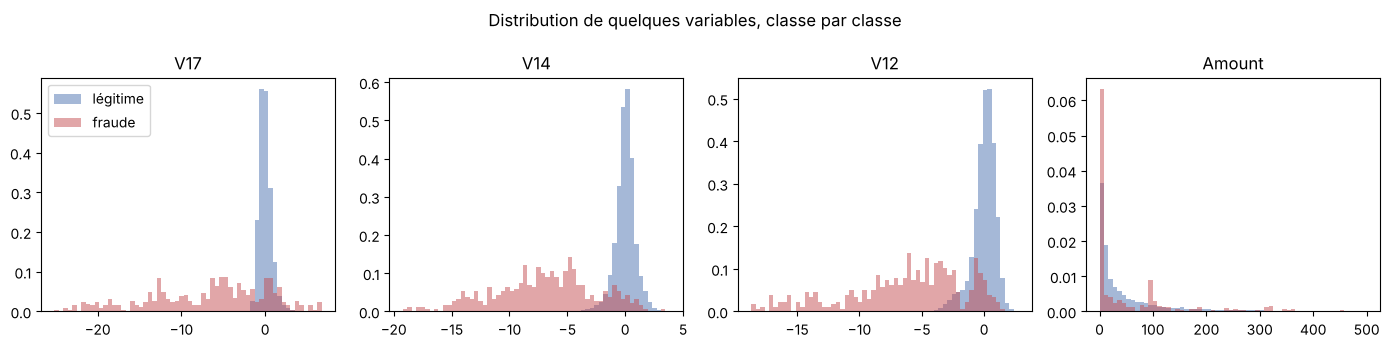

In [9]:
# distributions superposées : density=True, sinon les 492 fraudes seraient invisibles
variables = list(par_classe.index[:3]) + ["Amount"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, variables):
    bornes = (min(legitimes[col].quantile(0.001), fraudes[col].min()),
              max(legitimes[col].quantile(0.999), fraudes[col].max()))
    if col == "Amount":
        bornes = (0, 500)    # le montant est très étalé : on regarde les 500 premiers euros
    ax.hist(legitimes[col], bins=60, range=bornes, density=True, alpha=0.5,
            color="#4C72B0", label="légitime")
    ax.hist(fraudes[col], bins=60, range=bornes, density=True, alpha=0.5,
            color="#C44E52", label="fraude")
    ax.set_title(col)
axes[0].legend()
plt.suptitle("Distribution de quelques variables, classe par classe")
plt.tight_layout()
plt.show()

**Lecture.**
1. **Deux groupes de tailles très différentes** : 284 315 transactions légitimes contre 492 fraudes.
   Les doublons touchent surtout les légitimes (1 062) mais aussi 19 fraudes : après leur
   suppression, il reste 473 fraudes.
2. **Les fraudes se distinguent nettement sur quelques composantes.** Leur moyenne est bien plus
   basse sur `V17` (écart standardisé −7,9), `V14` (−7,3), `V12` (−6,3), `V10` (−5,2) et `V16`
   (−4,7), et plus haute sur `V11` (+3,7) et `V4` (+3,2). Sur les histogrammes, les deux
   distributions se chevauchent peu pour ces variables : ce sont elles qui permettront aux
   modèles de reconnaître une fraude. Ce sont aussi les variables les plus corrélées avec `Class`
   (exercice 4).
3. **D'autres variables ne distinguent presque pas les classes** : `V22`, `V23`, `V25`, `V15`
   ou `V26` ont presque la même moyenne dans les deux groupes (écart standardisé ≤ 0,11).
4. **Le montant est trompeur.** La moyenne des fraudes est plus élevée (122 € contre 88 €), mais
   leur médiane est plus basse (9,25 € contre 22 €) : la plupart des fraudes portent sur de petits
   montants, et quelques fraudes élevées tirent la moyenne vers le haut. Il faut donc regarder la
   distribution, pas seulement la moyenne.
5. **`Time` distingue peu les classes en moyenne** (écart standardisé −0,30), mais pas l'heure :
   25 % des fraudes ont lieu dans les heures creuses (heures 0 à 5 de chaque journée, probablement
   la nuit), contre 8 % des transactions légitimes. Dans ces heures, le taux de fraude atteint
   0,52 %, contre 0,14 % le reste du temps.

In [10]:
# vérification de la remarque sur l'heure (Time est en secondes depuis la 1re transaction)
heure = (donnees["Time"] // 3600) % 24
creuses = heure.isin(range(6))
print(f"part des transactions en heures creuses : légitimes {creuses[donnees[CIBLE] == 0].mean():.1%}"
      f", fraudes {creuses[donnees[CIBLE] == 1].mean():.1%}")
print(f"taux de fraude : heures creuses {donnees.loc[creuses, CIBLE].mean():.3%}"
      f", reste du temps {donnees.loc[~creuses, CIBLE].mean():.3%}")

part des transactions en heures creuses : légitimes 8.4%, fraudes 25.2%
taux de fraude : heures creuses 0.518%, reste du temps 0.141%


**Ce qu'on en retient pour la suite :** on garde les deux classes dans le même jeu de données (les
modèles ont besoin des deux pour apprendre à les distinguer), mais on vérifie que la séparation
entraînement/test conserve la proportion de chaque classe — c'est la **stratification** de
l'exercice 2.

## Exercice 2 — préparer sans faire fuir l'information

`preparer(donnees)`, dans cet ordre :
0. supprimer les doublons (ajout propre à ce jeu de données) ;
1. écarter les lignes dépourvues de toutes les mesures ;
2. construire `X` (les colonnes de `MESURES`, puis celles de `CATEGORIES`) et `y` (la colonne `CIBLE`) ;
3. séparer avec `train_test_split(..., test_size=0.2, random_state=GRAINE, stratify=y)` ;
4. construire un `ColumnTransformer` : médiane puis standardisation pour les colonnes numériques
   (et, s'il y en avait, constante `"inconnu"` puis `OneHotEncoder` pour les catégorielles) ;
5. l'ajuster **sur l'entraînement seulement**, puis transformer les deux sous-ensembles.

La fonction renvoie `(X_train, X_test, y_train, y_test, preparateur)`.

In [11]:
def preparer(donnees):
    propres = donnees.drop_duplicates()
    propres = propres[~propres[MESURES].isna().all(axis=1)].copy()
    X = propres[MESURES + CATEGORIES]
    y = propres[CIBLE]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=GRAINE, stratify=y)
    numerique = Pipeline([("imputation", SimpleImputer(strategy="median")),
                          ("echelle", StandardScaler())])
    transformateurs = [("num", numerique, MESURES)]
    if CATEGORIES:   # vide pour ce jeu de données
        categoriel = Pipeline([("imputation", SimpleImputer(strategy="constant", fill_value="inconnu")),
                               ("encodage", OneHotEncoder(handle_unknown="ignore"))])
        transformateurs.append(("cat", categoriel, CATEGORIES))
    preparateur = ColumnTransformer(transformateurs)
    preparateur.fit(X_train)                       # ajusté sur l'entraînement SEULEMENT
    return (np.asarray(preparateur.transform(X_train)),
            np.asarray(preparateur.transform(X_test)),
            y_train, y_test, preparateur)


X_train, X_test, y_train, y_test, preparateur = preparer(donnees)
print("entraînement :", X_train.shape, "  test :", X_test.shape)
print("fraudes en entraînement :", int(y_train.sum()), f"({y_train.mean():.4%})")
print("fraudes en test         :", int(y_test.sum()), f"({y_test.mean():.4%})")

entraînement : (226980, 30)   test : (56746, 30)
fraudes en entraînement : 378 (0.1665%)
fraudes en test         : 95 (0.1674%)


In [12]:
_num_train = X_train[:, :len(MESURES)]
_num_test = X_test[:, :len(MESURES)]
verifier("L01-E2", X_train.shape[0] + X_test.shape[0] == len(donnees.drop_duplicates()),
         "des lignes ont été perdues ou ajoutées")
verifier("L01-E2", X_train.shape[1] == X_test.shape[1] == len(MESURES),
         "les deux sous-ensembles n'ont pas le même nombre de colonnes")
verifier("L01-E2", abs(y_train.mean() - y_test.mean()) < 0.0005,
         "la proportion de fraudes diffère entre entraînement et test : pas stratifié")
verifier("L01-E2", abs(_num_train.mean()) < 1e-8 and abs(_num_train.std() - 1) < 1e-6,
         "l'entraînement n'est pas centré-réduit")
verifier("L01-E2", abs(_num_test.mean()) > 1e-6,
         "le test est exactement centré : le préparateur a vu le test (fuite)")

[L01-E2] OK
[L01-E2] OK
[L01-E2] OK
[L01-E2] OK
[L01-E2] OK


**Lecture.** `stratify=y` conserve la proportion de fraudes (≈ 0,17 %) dans les deux
sous-ensembles ; sans cette option, le tirage pourrait donner un test presque sans fraude.
Le dernier contrôle se lit comme dans le corrigé : l'entraînement est exactement centré, le test ne
l'est pas, car il subit la moyenne et l'écart-type de l'entraînement. Un test parfaitement centré
serait le symptôme d'une fuite.

## Exercice 3 — mesurer ce que la fuite change

`parametres_echelle(X_train_num, X_test_num)` renvoie un triplet :
1. les moyennes apprises par un `StandardScaler` ajusté sur l'entraînement seul ;
2. les moyennes apprises sur la concaténation entraînement + test ;
3. l'écart maximal, en valeur absolue, entre les deux vecteurs.

Les entrées sont les colonnes numériques **brutes** (non standardisées), déjà imputées. On réutilise
la séparation de l'exercice 2 par les index de `y_train` et `y_test`, pour parler des mêmes
transactions.

In [13]:
_mediane = donnees.loc[y_train.index, MESURES].median()
X_train_num = donnees.loc[y_train.index, MESURES].fillna(_mediane).to_numpy(dtype=float)
X_test_num = donnees.loc[y_test.index, MESURES].fillna(_mediane).to_numpy(dtype=float)
print("colonnes numériques brutes :", X_train_num.shape, X_test_num.shape)


def parametres_echelle(X_train_num, X_test_num):
    sur_train = StandardScaler().fit(X_train_num).mean_
    sur_tout = StandardScaler().fit(np.vstack([X_train_num, X_test_num])).mean_
    return sur_train, sur_tout, float(np.max(np.abs(sur_train - sur_tout)))


sur_train, sur_tout, ecart = parametres_echelle(X_train_num, X_test_num)
for nom in ["Amount", "Time"]:
    i = MESURES.index(nom)
    print(f"{nom:<7} moyenne (entraînement) : {sur_train[i]:12.4f}   (tout) : {sur_tout[i]:12.4f}"
          f"   écart : {abs(sur_train[i] - sur_tout[i]):.4f}")
print("écart maximal sur les 30 colonnes :", round(ecart, 4))

colonnes numériques brutes : (226980, 30) (56746, 30)
Amount  moyenne (entraînement) :      88.3090   (tout) :      88.4727   écart : 0.1637
Time    moyenne (entraînement) :   94750.9389   (tout) :   94811.0776   écart : 60.1387
écart maximal sur les 30 colonnes : 60.1387


In [14]:
verifier("L01-E3", np.asarray(sur_train).shape == (len(MESURES),),
         "le vecteur de moyennes n'a pas une valeur par mesure")
verifier("L01-E3", np.allclose(sur_train, X_train_num.mean(axis=0), atol=1e-8),
         "les moyennes ajustées sur l'entraînement ne sont pas celles de l'entraînement")
verifier("L01-E3", ecart > 0,
         "les deux ajustements donnent les mêmes moyennes : le second n'a pas vu le test")

[L01-E3] OK
[L01-E3] OK
[L01-E3] OK


**Lecture.** Les deux vecteurs de moyennes diffèrent : le test a bougé les paramètres. Avec plus
de 280 000 lignes, l'écart est faible (quelques centimes sur `Amount`, une minute sur `Time`) — et
c'est précisément ce qui rend la fuite dangereuse : elle ne fait pas exploser les résultats, elle les
embellit discrètement.

Dans ce jeu de données, le vrai risque de fuite est ailleurs : les **doublons** (retirés avant la
séparation) et, plus tard, le **rééquilibrage SMOTE**, qui est lui aussi un traitement appris et doit
être appliqué **sur l'entraînement seulement**. En pratique, on met tout dans un `Pipeline` et on ne
l'ajuste qu'une fois, sur l'entraînement.

## Exercice 4 — une corrélation peut mentir

Dans le lab, la variable cachée était l'**espèce**. Ici, c'est la **classe** : légitime ou fraude.

`correlations_par_classe(donnees, a, b)` renvoie :
1. le coefficient de corrélation linéaire entre les colonnes `a` et `b` sur toutes les données ;
2. un dictionnaire donnant ce même coefficient **classe par classe**.

On l'applique d'abord à toutes les paires de caractéristiques pour trouver celle où le coefficient
global et le coefficient chez les fraudes diffèrent le plus, puis on regarde les résultats côte à côte
et on **trace** avant d'interpréter.

In [15]:
NOMS_CLASSES = {0: "légitime", 1: "fraude"}


def correlations_par_classe(donnees, a, b):
    r_global = float(donnees[a].corr(donnees[b]))
    par_classe = {NOMS_CLASSES[int(classe)]: float(groupe[a].corr(groupe[b]))
                  for classe, groupe in donnees.groupby(CIBLE)}
    return r_global, par_classe

In [16]:
# matrices de corrélation : toutes les données, puis chaque classe séparément
corr_tout = donnees[MESURES].corr()
corr_legit = donnees.loc[donnees[CIBLE] == 0, MESURES].corr()
corr_fraude = donnees.loc[donnees[CIBLE] == 1, MESURES].corr()

# toutes les paires (triangle supérieur), classées par écart entre global et fraude
haut = np.triu(np.ones(corr_tout.shape, dtype=bool), k=1)
paires = pd.DataFrame({
    "r global": corr_tout.where(haut).stack(),
    "r légitime": corr_legit.where(haut).stack(),
    "r fraude": corr_fraude.where(haut).stack(),
})
paires["écart fraude - global"] = (paires["r fraude"] - paires["r global"]).abs()
paires = paires.sort_values("écart fraude - global", ascending=False)
print("paires où le coefficient global cache le plus la relation chez les fraudes :")
print(paires.head(10).to_string(float_format="%+.3f"))

A, B = paires.index[0]          # paire retenue pour l'exercice
A2, B2 = paires.index[1]        # paire de réserve pour le travail à domicile
print(f"\npaire retenue : {A} / {B}")

paires où le coefficient global cache le plus la relation chez les fraudes :
         r global  r légitime  r fraude  écart fraude - global
V17 V18    -0.000      -0.097    +0.971                 +0.971
V16 V17    -0.000      -0.146    +0.960                 +0.960
    V18    -0.000      -0.049    +0.944                 +0.944
V1  V3     -0.000      -0.048    +0.908                 +0.908
    V7     -0.000      -0.054    +0.898                 +0.898
    V5     -0.000      -0.031    +0.895                 +0.895
V11 V12    +0.000      +0.064    -0.890                 +0.890
V3  V5     -0.000      -0.049    +0.884                 +0.884
    V7     +0.000      -0.085    +0.882                 +0.882
V12 V16    -0.000      -0.090    +0.882                 +0.882

paire retenue : V17 / V18


In [17]:
r_global, par_classe = correlations_par_classe(donnees, A, B)
verifier("L01-E4", set(par_classe) == {"légitime", "fraude"},
         "les deux classes ne sont pas toutes présentes dans le dictionnaire")
verifier("L01-E4", abs(r_global - donnees[A].corr(donnees[B])) < 1e-9,
         "la corrélation globale ne correspond pas aux données")
verifier("L01-E4", abs(par_classe["fraude"] - r_global) > 0.1,
         "le coefficient chez les fraudes est proche du global : le calcul n'est peut-être pas "
         "fait à l'intérieur de chaque classe")

[L01-E4] OK
[L01-E4] OK
[L01-E4] OK


corrélation sur toutes les données : -0.000
    légitime  -0.097
    fraude    +0.971


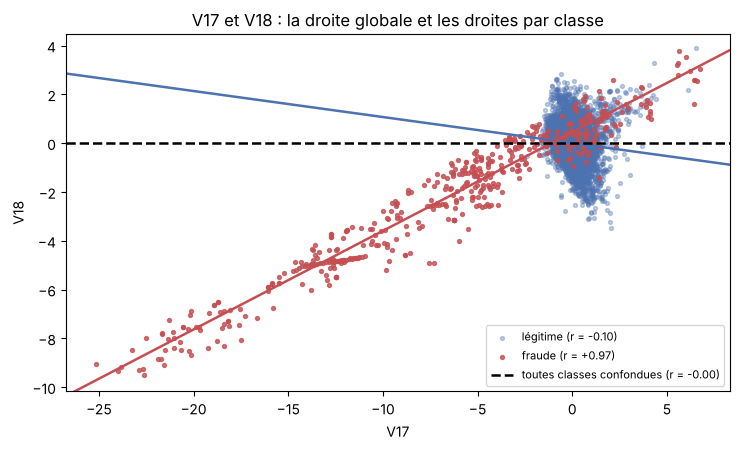

In [18]:
def tracer_par_classe(donnees, a, b):
    r_global, par_classe = correlations_par_classe(donnees, a, b)
    print(f"corrélation sur toutes les données : {r_global:+.3f}")
    for nom, r in par_classe.items():
        print(f"    {nom:<9} {r:+.3f}")

    # 284 000 points sont illisibles : on dessine 5 000 légitimes tirés au hasard + toutes les fraudes.
    # Les droites, elles, sont calculées sur TOUTES les transactions de chaque classe.
    legit = donnees[donnees[CIBLE] == 0]
    fraude = donnees[donnees[CIBLE] == 1]
    echantillon = legit.sample(n=min(5000, len(legit)), random_state=GRAINE)
    # axes : le gros du nuage légitime + TOUTES les fraudes (elles sont souvent extrêmes)
    def bornes(col):
        bas = min(legit[col].quantile(0.005), fraude[col].min())
        haut = max(legit[col].quantile(0.995), fraude[col].max())
        marge = 0.05 * (haut - bas)
        return bas - marge, haut + marge
    grille = np.array(bornes(a))

    plt.figure(figsize=(7.5, 4.6))
    for nom, groupe, trace, couleur in [("légitime", legit, echantillon, "#4C72B0"),
                                        ("fraude", fraude, fraude, "#C44E52")]:
        plt.scatter(trace[a], trace[b], s=8, alpha=0.35 if nom == "légitime" else 0.8,
                    color=couleur, label=f"{nom} (r = {par_classe[nom]:+.2f})")
        p = np.polyfit(groupe[a], groupe[b], 1)
        plt.plot(grille, np.polyval(p, grille), color=couleur, lw=1.8)
    pg = np.polyfit(donnees[a], donnees[b], 1)
    plt.plot(grille, np.polyval(pg, grille), color="black", ls="--", lw=1.8,
             label=f"toutes classes confondues (r = {r_global:+.2f})")
    plt.xlim(grille)
    plt.ylim(bornes(b))
    plt.xlabel(a)
    plt.ylabel(b)
    plt.title(f"{a} et {b} : la droite globale et les droites par classe")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


tracer_par_classe(donnees, A, B)

**Question d'interprétation.** Comparez le coefficient global et les deux coefficients par
classe. Expliquez l'écart à partir de la figure : que fait la classe dans cette affaire ? Puis dites ce
que vous auriez conclu, à tort, en ne regardant que le coefficient global — et ce que cela implique
avant de faire confiance à une matrice de corrélation.

**Éléments de réponse** (résultats obtenus : `V17` / `V18`, r global = −0,000 ; légitimes −0,097 ;
fraudes +0,971).
- **Le coefficient global est nul.** C'est garanti par construction : `V1`…`V28` sont les composantes
  d'une ACP calculée sur l'ensemble des transactions, et une ACP produit des composantes **non
  corrélées** entre elles. Les dix paires du classement ont toutes un r global de ±0,000.
- **Chez les transactions légitimes**, le lien est faible et **négatif** (−0,10) : la droite bleue
  descend légèrement.
- **Chez les fraudes**, le lien est très fort et **positif** (+0,97) : les points rouges s'alignent
  presque parfaitement sur une droite qui monte, loin du nuage bleu (jusqu'à −25 sur `V17`).
- **Pourquoi le global vaut 0 :** les deux liens sont de signes contraires et se compensent
  exactement — c'est le cas « deux liens contraires qui s'annulent » du corrigé. La classe joue le rôle
  de l'espèce chez les manchots : c'est une **variable cachée** qui agit sur les deux mesures à la fois.
- **Conclusion fausse évitée :** en ne regardant que le coefficient global, on aurait écrit « `V17` et
  `V18` n'ont aucun lien ». C'est faux pour chacune des deux classes, et surtout pour les fraudes,
  celles que l'on veut détecter. Le phénomène n'est pas isolé : `V16`/`V17` (+0,96), `V1`/`V3`
  (+0,91) ou `V11`/`V12` (−0,89) montrent la même chose chez les fraudes.

**Trois conséquences pratiques pour le projet :**
- une matrice de corrélation calculée sur des groupes mélangés peut masquer, voire inverser, une
  relation — ici, la matrice globale est vide alors que les fraudes ont une structure très forte ;
- un coefficient proche de zéro ne signifie pas « pas de lien » : il peut signifier « lien présent
  dans un seul groupe », « lien non linéaire » ou « deux liens contraires qui s'annulent » ;
- avant d'interpréter, on trace, et on calcule les corrélations **par classe**. On ne retire donc
  aucune variable sur la seule base d'une corrélation globale faible : on garde les 30
  caractéristiques.

### Complément — corrélation de chaque caractéristique avec la cible

Pour le rapport, on regarde aussi le lien de chaque caractéristique avec `Class`
(corrélation dite *point-bisériale*, car `Class` vaut 0 ou 1). Les coefficients sont **petits en valeur
absolue** à cause du déséquilibre : on les classe, on ne les interprète pas comme une force de lien.
Calcul fait sur l'entraînement seulement, pour ne pas choisir de variables en regardant le test.

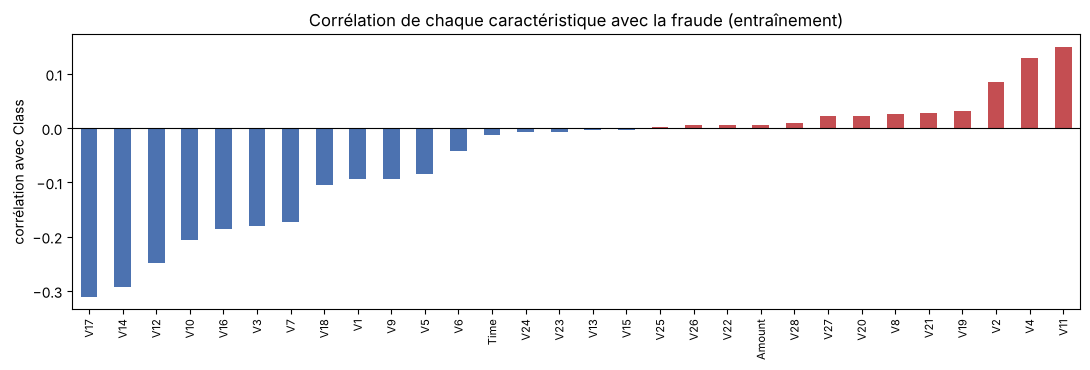

les 5 plus fortes en valeur absolue :
V17   -0.311
V14   -0.293
V12   -0.249
V10   -0.206
V16   -0.186


In [19]:
train = donnees.loc[y_train.index, MESURES + [CIBLE]]
lien_cible = train[MESURES].corrwith(train[CIBLE]).sort_values()
couleurs = ["#C44E52" if v > 0 else "#4C72B0" for v in lien_cible]
fig, ax = plt.subplots(figsize=(11, 3.8))
lien_cible.plot.bar(ax=ax, color=couleurs)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("corrélation avec Class")
ax.set_title("Corrélation de chaque caractéristique avec la fraude (entraînement)")
ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()
print("les 5 plus fortes en valeur absolue :")
print(lien_cible.reindex(lien_cible.abs().sort_values(ascending=False).index).head(5)
      .to_string(float_format="%+.3f"))

## Exercice 5 — choisir un modèle

On compare trois candidats avec **la même méthode** et **la même métrique**, puis on garde le meilleur :
- **Régression Logistique** : le modèle de référence (*baseline*), simple et rapide ;
- **Random Forest** : de nombreux arbres de décision qui votent ;
- **XGBoost** : des arbres construits les uns après les autres, chacun corrigeant les erreurs du
  précédent.

**Règles suivies** (celles des exercices 2 et 3) :
1. **Métrique principale : l'AUPRC** (aire sous la courbe précision-rappel, `average_precision`).
   L'exactitude est inutile ici : prédire toujours « légitime » donne 99,83 %. On regarde aussi la
   précision, le rappel et le F1.
2. **Validation croisée stratifiée à 5 plis, sur l'entraînement seulement.** Le jeu de test n'est
   pas utilisé pour choisir.
3. **Tout est dans un seul `Pipeline`** : préparateur → SMOTE → modèle. À chaque pli, la
   standardisation et SMOTE sont donc appris sur la partie d'entraînement du pli seulement, jamais
   sur la partie de validation. C'est la règle anti-fuite de l'exercice 3 appliquée à SMOTE.

Le pipeline de `imblearn` est nécessaire, car celui de scikit-learn n'accepte pas SMOTE
(`pip install imbalanced-learn xgboost` si besoin).

In [20]:
import time
from imblearn.over_sampling import SMOTE
from matplotlib.colors import LogNorm
from imblearn.pipeline import Pipeline as PipelineImb
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

# données brutes (non standardisées) : le préparateur est refait DANS chaque pli
X_tr_brut = donnees.loc[y_train.index, MESURES]
X_te_brut = donnees.loc[y_test.index, MESURES]

candidats = {
    "Régression Logistique": LogisticRegression(max_iter=1000),
    # max_samples=0.25 : chaque arbre voit un quart des lignes (sinon l'entraînement est très long)
    "Random Forest": RandomForestClassifier(n_estimators=100, max_samples=0.25,
                                            n_jobs=-1, random_state=GRAINE),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                             eval_metric="aucpr", n_jobs=-1, random_state=GRAINE),
}


def construire_pipeline(modele):
    return PipelineImb([
        ("preparation", clone(preparateur)),          # médiane + standardisation (exercice 2)
        ("smote", SMOTE(random_state=GRAINE)),        # rééquilibrage, entraînement seulement
        ("modele", modele),
    ])

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
metriques = {"AUPRC": "average_precision", "précision": "precision",
             "rappel": "recall", "F1": "f1", "ROC-AUC": "roc_auc"}

resultats_cv = {}
for nom, modele in candidats.items():
    debut = time.time()
    scores = cross_validate(construire_pipeline(modele), X_tr_brut, y_train,
                            cv=cv, scoring=metriques, n_jobs=1)
    resultats_cv[nom] = scores
    print(f"{nom:<22} AUPRC = {scores['test_AUPRC'].mean():.3f} ± {scores['test_AUPRC'].std():.3f}"
          f"   ({time.time() - debut:.0f} s)")

Régression Logistique  AUPRC = 0.716 ± 0.064   (12 s)


Random Forest          AUPRC = 0.822 ± 0.039   (222 s)


XGBoost                AUPRC = 0.836 ± 0.033   (55 s)


In [22]:
# tableau récapitulatif : moyenne ± écart-type sur les 5 plis
tableau = pd.DataFrame({
    nom: {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in metriques}
    for nom, s in resultats_cv.items()
}).T
tableau

,AUPRC,précision,rappel,F1,ROC-AUC
Régression Logistique,0.716 ± 0.064,0.054 ± 0.003,0.910 ± 0.020,0.102 ± 0.006,0.973 ± 0.011
Random Forest,0.822 ± 0.039,0.772 ± 0.070,0.815 ± 0.045,0.792 ± 0.054,0.977 ± 0.009
XGBoost,0.836 ± 0.033,0.735 ± 0.051,0.823 ± 0.036,0.775 ± 0.039,0.976 ± 0.008


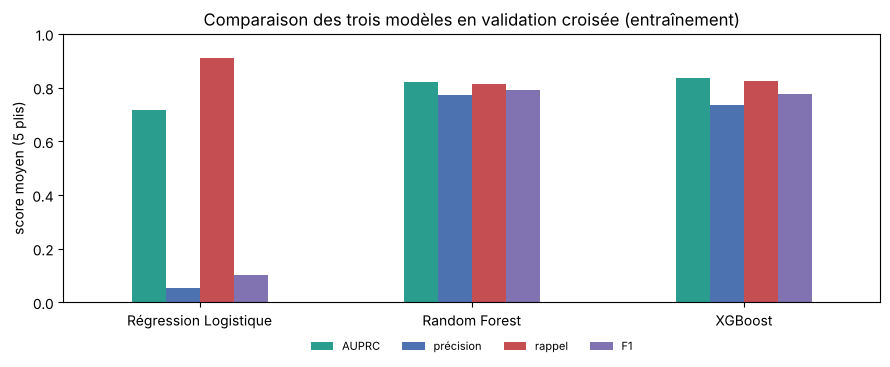

In [23]:
moyennes = pd.DataFrame({nom: {m: s["test_" + m].mean() for m in metriques}
                         for nom, s in resultats_cv.items()}).T
ax = moyennes[["AUPRC", "précision", "rappel", "F1"]].plot.bar(figsize=(9, 3.8), rot=0,
                                                               color=["#2A9D8F", "#4C72B0", "#C44E52", "#8172B2"])
ax.set_ylim(0, 1)
ax.set_ylabel("score moyen (5 plis)")
ax.set_title("Comparaison des trois modèles en validation croisée (entraînement)")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
plt.show()

In [24]:
verifier("L01-E5", set(resultats_cv) == set(candidats),
         "les trois modèles n'ont pas tous été évalués")
verifier("L01-E5", all(len(s["test_AUPRC"]) == 5 for s in resultats_cv.values()),
         "la validation croisée n'a pas 5 plis")
verifier("L01-E5", [n for n, _ in construire_pipeline(LogisticRegression()).steps]
         == ["preparation", "smote", "modele"],
         "SMOTE et la préparation ne sont pas dans le pipeline : ils verraient les plis de validation")
verifier("L01-E5", len(X_tr_brut) == len(y_train) and X_tr_brut.index.isin(y_test.index).sum() == 0,
         "des transactions du test ont servi à la validation croisée")

[L01-E5] OK
[L01-E5] OK
[L01-E5] OK
[L01-E5] OK


In [25]:
# choix : la meilleure AUPRC moyenne en validation croisée
choisi = moyennes["AUPRC"].idxmax()
print("modèle retenu :", choisi)
print(moyennes.sort_values("AUPRC", ascending=False).to_string(float_format="%.3f"))

modèle retenu : XGBoost
                       AUPRC  précision  rappel    F1  ROC-AUC
XGBoost                0.836      0.735   0.823 0.775    0.976
Random Forest          0.822      0.772   0.815 0.792    0.977
Régression Logistique  0.716      0.054   0.910 0.102    0.973


### Évaluation finale du modèle retenu sur le jeu de test

Le modèle choisi est réentraîné sur **tout** le jeu d'entraînement, puis évalué **une seule fois**
sur le jeu de test (56 746 transactions, dont 95 fraudes), qui n'a servi à aucun choix. C'est cette
mesure-là que l'on peut annoncer comme performance attendue sur de nouvelles transactions.

In [26]:
final = construire_pipeline(clone(candidats[choisi])).fit(X_tr_brut, y_train)
proba = final.predict_proba(X_te_brut)[:, 1]
prediction = (proba >= 0.5).astype(int)

score_test = {
    "AUPRC": average_precision_score(y_test, proba),
    "précision": precision_score(y_test, prediction),
    "rappel": recall_score(y_test, prediction),
    "F1": f1_score(y_test, prediction),
}
print(f"{choisi} — jeu de test (seuil 0,5)")
for m, v in score_test.items():
    print(f"    {m:<10} {v:.3f}")

vn, fp, fn, vp = confusion_matrix(y_test, prediction).ravel()
print()
print(f"fraudes détectées      : {vp} sur {vp + fn}")
print(f"fraudes manquées       : {fn}")
print(f"fausses alertes        : {fp} sur {vn + fp} transactions légitimes")

XGBoost — jeu de test (seuil 0,5)
    AUPRC      0.866
    précision  0.683
    rappel     0.863
    F1         0.763

fraudes détectées      : 82 sur 95
fraudes manquées       : 13
fausses alertes        : 38 sur 56651 transactions légitimes


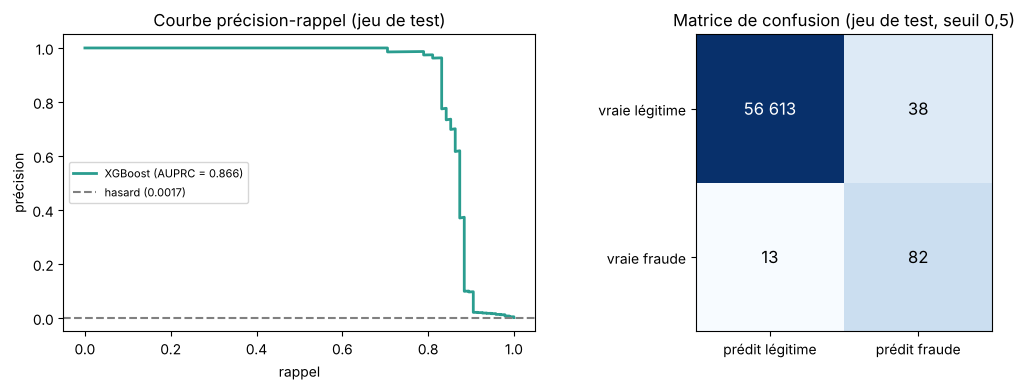

In [27]:
precision_c, rappel_c, _ = precision_recall_curve(y_test, proba)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(rappel_c, precision_c, color="#2A9D8F", lw=2,
           label=f"{choisi} (AUPRC = {score_test['AUPRC']:.3f})")
ax[0].axhline(y_test.mean(), color="grey", ls="--", label=f"hasard ({y_test.mean():.4f})")
ax[0].set_xlabel("rappel")
ax[0].set_ylabel("précision")
ax[0].set_title("Courbe précision-rappel (jeu de test)")
ax[0].legend(fontsize=8)

matrice = np.array([[vn, fp], [fn, vp]])
ax[1].imshow(matrice, cmap="Blues", norm=LogNorm())
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f"{matrice[i, j]:,}".replace(",", " "), ha="center", va="center",
                   color="white" if matrice[i, j] > 1000 else "black", fontsize=12)
ax[1].set_xticks([0, 1])
ax[1].set_xticklabels(["prédit légitime", "prédit fraude"])
ax[1].set_yticks([0, 1])
ax[1].set_yticklabels(["vraie légitime", "vraie fraude"])
ax[1].set_title("Matrice de confusion (jeu de test, seuil 0,5)")
plt.tight_layout()
plt.show()

**Lecture des résultats.**

| Modèle (validation croisée, 5 plis) | AUPRC | précision | rappel | F1 |
|---|---|---|---|---|
| Régression Logistique | 0,716 ± 0,064 | 0,054 | 0,910 | 0,102 |
| Random Forest | 0,822 ± 0,039 | 0,772 | 0,815 | 0,792 |
| **XGBoost** | **0,836 ± 0,033** | 0,735 | 0,823 | 0,775 |

1. **La Régression Logistique sert de référence, et elle est battue nettement.** Elle détecte 91 % des
   fraudes, mais sa précision n'est que de 5 % : sur 100 alertes, 95 sont fausses. Avec SMOTE, elle
   déclare « fraude » beaucoup trop souvent. Son ROC-AUC (0,973) paraît excellent : c'est la preuve
   que le ROC-AUC est trompeur avec un tel déséquilibre, et qu'il faut regarder l'AUPRC.
2. **Les deux modèles à base d'arbres sont bien meilleurs** (AUPRC > 0,82), avec un bon équilibre
   entre précision et rappel. Ils exploitent les liens non linéaires et les structures propres aux
   fraudes vues à l'exercice 4.
3. **Nous retenons XGBoost** : il a la meilleure AUPRC moyenne (0,836) et la plus stable d'un pli à
   l'autre (± 0,033). Il est aussi quatre fois plus rapide à entraîner que Random Forest (53 s contre
   216 s). **Nuance honnête :** l'écart avec Random Forest (0,014) est plus petit que leur
   écart-type ; Random Forest a même un F1 légèrement meilleur au seuil 0,5. Les deux modèles sont
   donc très proches, et XGBoost l'emporte sur le critère fixé à l'avance (AUPRC).
4. **Sur le jeu de test**, jamais vu pendant le choix, XGBoost obtient une AUPRC de 0,866 : il détecte
   **82 fraudes sur 95** (rappel 86 %), en manque 13, et ne déclenche que **38 fausses alertes sur
   56 651** transactions légitimes (précision 68 %). Le score de test est proche de celui de la
   validation croisée : le modèle généralise bien, et il n'y a pas de signe de fuite.

**Suite possible :** ajuster les hyperparamètres de XGBoost (par validation croisée, toujours sur
l'entraînement) et choisir le seuil de décision selon le coût d'une fraude manquée par rapport à
celui d'une fausse alerte.

## Bilan

- Le diagnostic précède le traitement, et peut conclure qu'il ne faut pas traiter : ici, les valeurs
  aberrantes sont gardées, car elles caractérisent souvent les fraudes.
- Les doublons (1 081 lignes) sont retirés **avant** la séparation, sinon une même transaction serait
  à la fois dans l'entraînement et dans le test.
- Tout paramètre de préparation — médiane, moyenne, écart-type, et plus tard SMOTE — est appris,
  donc appris sur l'entraînement seul. Un test parfaitement centré est un symptôme de fuite.
- Une corrélation calculée sur des classes mélangées peut dire autre chose que la vérité : pour
  `V17` / `V18`, le coefficient global est nul alors qu'il vaut −0,10 chez les légitimes et +0,97 chez
  les fraudes. On trace, et on regarde par classe, avant d'interpréter.
- Pour choisir un modèle, on compare les candidats en validation croisée sur l'entraînement, avec
  SMOTE dans le pipeline, et on n'utilise le test qu'une fois, à la fin. XGBoost est retenu
  (AUPRC 0,836 en validation croisée, 0,866 sur le test).
- Avec la cible, les caractéristiques les plus corrélées sont `V17` (−0,31), `V14` (−0,29), `V12`
  (−0,25), `V10` (−0,21) et `V16` (−0,19) ; `V11` (+0,15) et `V4` (+0,13) sont les plus liées
  positivement.

## À domicile

Reprenez l'exercice 4 avec la deuxième paire du classement (`A2`, `B2`, cellule suivante).
L'écart entre le coefficient global et le coefficient chez les fraudes se produit-il aussi ?
Rédigez votre conclusion en trois phrases.

paire à domicile : V16 / V17
corrélation sur toutes les données : -0.000
    légitime  -0.146
    fraude    +0.960


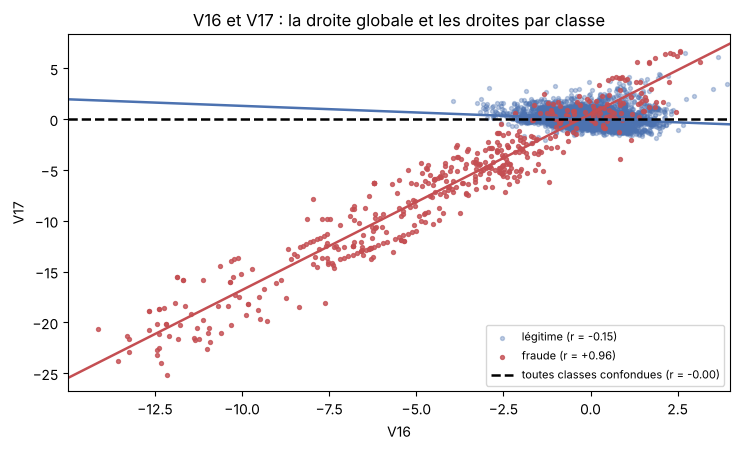

In [28]:
print(f"paire à domicile : {A2} / {B2}")
tracer_par_classe(donnees, A2, B2)

**Conclusion (trois phrases).**

1. Oui, le phénomène se reproduit pour `V16` / `V17` : le coefficient global est nul (−0,000), il est
   faiblement négatif chez les transactions légitimes (−0,15) et très fortement positif chez les
   fraudes (+0,96).
2. Les deux liens, de signes contraires, s'annulent dans le coefficient global, qui ne dit donc rien de
   la relation qui existe à l'intérieur de chaque classe.
3. Pour ce projet, on ne juge donc jamais une variable sur sa corrélation globale : on trace et on
   calcule par classe, et on garde les 30 caractéristiques, dont la structure propre aux fraudes est
   justement ce que les modèles devront apprendre.